In [2]:
"""
基于特征的谣言检测 - 完整实验代码
数据集：CSDC-Rumor（微博不实信息 + 腾讯/丁香园谣言数据）
方法：特征工程 + 机器学习分类器（逻辑回归 / 随机森林）
"""

import json
import re
import os
import glob
import pandas as pd
import numpy as np
import jieba
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from snownlp import SnowNLP
import warnings
warnings.filterwarnings('ignore')

# 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

### 数据概览

In [8]:
from collections import Counter
from pprint import pprint

# 路径配置
DATA_DIR = "rumor"                     # 数据根目录
RUMOR_WEIBO_DIR = os.path.join(DATA_DIR, "rumor_weibo")   # 微博谣言文件夹
FACT_JSON_PATH = os.path.join(DATA_DIR, "fact.json")      # 腾讯/丁香园数据

# ========== 1. 微博数据概览 ==========
print("=" * 60)
print("1. 微博谣言数据 (rumor_weibo)")
print("=" * 60)

weibo_files = glob.glob(os.path.join(RUMOR_WEIBO_DIR, "*.json"))
print(f"文件数量: {len(weibo_files)}")

if weibo_files:
    with open(weibo_files[0], 'r', encoding='utf-8') as f:
        sample = json.load(f)
    # print(f"\n字段列表: {list(sample.keys())}")
    print("\n字段列表:")
    pprint(list(sample.keys()), width=60)  # width 控制每行最大字符数
    print(f"\n示例数据（只显示部分字段）:")
    print(f"  rumorCode: {sample.get('rumorCode', '')}")
    print(f"  title: {sample.get('title', '')[:80]}...")
    # 修正：处理 None 值
    rumor_text = sample.get('rumorText') or ''
    result_text = sample.get('result') or ''
    print(f"  rumorText 长度: {len(rumor_text)} 字符")
    print(f"  result 长度: {len(result_text)} 字符")
    print(f"  publishTime: {sample.get('publishTime', '')}")
    
    # 统计 rumorText 长度（跳过 None）
    lengths = []
    for fpath in weibo_files:
        try:
            with open(fpath, 'r', encoding='utf-8') as f:
                data = json.load(f)
                txt = data.get('rumorText')
                if txt and isinstance(txt, str):
                    lengths.append(len(txt))
        except:
            pass
    if lengths:
        print(f"\n非空谣言条数: {len(lengths)}")
        print(f"\n谣言文本长度: 最小={min(lengths)}, 最大={max(lengths)}, 平均={sum(lengths)/len(lengths):.0f}")
else:
    print("未找到微博数据文件，请检查路径。")

# ========== 2. 腾讯/丁香园数据概览 ==========
print("\n" + "=" * 60)
print("2. 腾讯/丁香园谣言-事实对数据 (fact.json)")
print("=" * 60)

if os.path.exists(FACT_JSON_PATH):
    with open(FACT_JSON_PATH, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    total_lines = len(lines)
    print(f"文件总行数: {total_lines}")
    
    # 解析前3行看结构
    sample_items = []
    for i, line in enumerate(lines[:3]):
        line = line.strip()
        if line:
            try:
                obj = json.loads(line)
                sample_items.append(obj)
            except:
                print(f"第{i+1}行解析失败")
    
    if sample_items:
        print(f"\n字段列表:{list(sample_items[0].keys())}")
    
        print("\n示例数据（第一条）:")
        first = sample_items[0]
        for k, v in first.items():
            if isinstance(v, str):
                v_str = v or ''
                print(f"  {k}: {v_str[:30]}{'...' if len(v_str)>30 else ''}")
            else:
                # 对于列表等非字符串类型，也可以限制显示长度
                v_repr = str(v)
                if len(v_repr) > 30:
                    v_repr = v_repr[:30] + '...'
                print(f"  {k}: {v_repr}")
                
    
    # 统计explain标签分布
    explain_counts = Counter()
    rumor_has_text = 0
    abstract_has_text = 0
    for line in lines:
        line = line.strip()
        if not line:
            continue
        try:
            obj = json.loads(line)
            explain = obj.get('explain', '')
            if explain:
                explain_counts[explain] += 1
            # 检查 rumor 和 abstract 是否存在且为非空字符串
            rumor = obj.get('rumor')
            abstract = obj.get('abstract')
            if rumor and isinstance(rumor, str):
                rumor_has_text += 1
            if abstract and isinstance(abstract, str):
                abstract_has_text += 1
        except:
            pass
    
    print(f"\n标签 'explain' 分布:")
    for label, cnt in explain_counts.most_common():
        print(f"  {label}: {cnt}")
    
    print(f"\n包含非空 'rumor' 的行数: {rumor_has_text}")
    print(f"包含非空 'abstract' 的行数: {abstract_has_text}")
    
    if rumor_has_text == total_lines and abstract_has_text == total_lines:
        print("\n✅ 每条数据同时包含谣言(rumor)和事实(abstract)文本，可构建平衡的谣言-事实对。")
    else:
        print("\n⚠️ 部分行缺少 rumor 或 abstract，需要过滤。")
else:
    print("未找到 fact.json 文件，请检查路径。")

# ========== 3. 整体建议 ==========
print("\n" + "=" * 60)
print("3. 数据整合建议")
print("=" * 60)

print(f"""
根据以上概览：
- 微博数据提供 {len(weibo_files)} 条纯谣言样本（需注意谣言文本可能为 None）。
- 腾讯/丁香园数据提供 {total_lines} 对谣言-事实文本（每行同时有 rumor 和 abstract，非空比例高）。

建议策略：
1. 如果希望正负样本平衡，可以只使用腾讯/丁香园的 {rumor_has_text} 条谣言和 {abstract_has_text} 条事实（共 {rumor_has_text + abstract_has_text} 条）。
2. 如果需要更多谣言样本，可以将微博的有效谣言（非空）加入，但事实样本仍只有 {abstract_has_text} 条，会造成类别不平衡。
3. 本实验后续推荐采用方案1（平衡数据集），便于模型训练和结果解释。
""")

1. 微博谣言数据 (rumor_weibo)
文件数量: 324

字段列表:
['rumorCode',
 'title',
 'informerName',
 'informerUrl',
 'rumormongerName',
 'rumormongerUrl',
 'rumorText',
 'visitTimes',
 'result',
 'publishTime',
 'related_url']

示例数据（只显示部分字段）:
  rumorCode: K1CaS7Qth660h
  title: @大不了不练了 投诉@口水垂涎三千尺 不实信息...
  rumorText 长度: 0 字符
  result 长度: 246 字符
  publishTime: 2020-01-22

非空谣言条数: 273

谣言文本长度: 最小=7, 最大=4753, 平均=576

2. 腾讯/丁香园谣言-事实对数据 (fact.json)
文件总行数: 124

字段列表:['date', 'explain', 'tag', 'abstract', 'title', 'rumor']

示例数据（第一条）:
  date: 2020-03-18
  explain: 尚无定论
  tag: ['新型冠状病毒', '易感人群']
  abstract: 研究没有正式发表，没有经过同行评议，所以不应被视为结论性的、...
  title: A型血更易感染新冠肺炎，O型血不易感
  rumor: 南方科技大学、上海交大、武汉中南医院、武汉金银潭医院等8家单...

标签 'explain' 分布:
  伪科学: 61
  尚无定论: 43
  确实如此: 19
  伪常识: 1

包含非空 'rumor' 的行数: 124
包含非空 'abstract' 的行数: 124

✅ 每条数据同时包含谣言(rumor)和事实(abstract)文本，可构建平衡的谣言-事实对。

3. 数据整合建议

根据以上概览：
- 微博数据提供 324 条纯谣言样本（需注意谣言文本可能为 None）。
- 腾讯/丁香园数据提供 124 对谣言-事实文本（每行同时有 rumor 和 abstract，非空比例高）。

建议策略：
1. 如果希望正负样本平衡，可以只使用腾讯/丁香园的 

### 数据加载

In [9]:
print("="*60)
print("平衡数据集实验 (谣言62 vs 事实62)")
print("="*60)

# ========== 1. 加载数据（只取伪科学/伪常识） ==========
DATA_DIR = "rumor"
FACT_JSON_PATH = os.path.join(DATA_DIR, "fact.json")

def load_balanced_pairs(filepath):
    rumors, facts = [], []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            explain = obj.get('explain', '')
            if explain not in ['伪科学', '伪常识']:
                continue
            rumor = obj.get('rumor', '').strip()
            abstract = obj.get('abstract', '').strip()
            if rumor and abstract:
                rumors.append(rumor)
                facts.append(abstract)
    return rumors, facts

rumor_texts, fact_texts = load_balanced_pairs(FACT_JSON_PATH)
print(f"谣言样本: {len(rumor_texts)}")
print(f"事实样本: {len(fact_texts)}")

all_texts = rumor_texts + fact_texts
all_labels = [1]*len(rumor_texts) + [0]*len(fact_texts)

# 去重（基于文本）
unique = {}
unique_texts, unique_labels = [], []
for t, l in zip(all_texts, all_labels):
    if t not in unique:
        unique[t] = True
        unique_texts.append(t)
        unique_labels.append(l)

print(f"去重后总样本: {len(unique_texts)} (谣言:{sum(unique_labels)}, 事实:{len(unique_labels)-sum(unique_labels)})")

平衡数据集实验 (谣言62 vs 事实62)
谣言样本: 62
事实样本: 62
去重后总样本: 123 (谣言:62, 事实:61)


In [10]:
'''
确认重复事实
'''
try:
    # 统计每个文本出现的次数
    text_counter = Counter(all_texts)
    duplicate_texts = [text for text, cnt in text_counter.items() if cnt > 1]
    
    print(f"重复的文本数量: {len(duplicate_texts)}")
    for dup in duplicate_texts:
        # 找出该文本的所有标签
        labels_for_dup = [all_labels[i] for i, t in enumerate(all_texts) if t == dup]
        print(f"\n文本: {dup[:200]}...")
        print(f"出现次数: {text_counter[dup]}")
        print(f"对应的标签: {labels_for_dup} (1=谣言, 0=事实)")
        if 0 in labels_for_dup and 1 in labels_for_dup:
            print("⚠️ 该文本同时出现在谣言和事实中！")
        elif len(set(labels_for_dup)) == 1:
            print("该文本只在同一类别内重复（内部重复）")
except NameError:
    print("变量 all_texts 或 all_labels 不存在，请重新运行数据加载部分。")

重复的文本数量: 1

文本: 我们常见的疾病，比如感冒、流感、病毒性肺炎主要是通过咳嗽、喷嚏以及空气播散的飞沫在人际间传播。其中上呼吸道中的鼻、咽粘膜上皮细胞是最初的感染部位，也就是咽喉处并不是造成感染的唯一部位。 不可否认喝水对身体的帮助，但是喝水保持咽喉湿润就能预防病毒没有任何依据，咽喉湿润也无法避免病毒会通过上呼吸道进入下呼吸道（支气管、肺部等），15分钟喝一次水更是不切实际。 相对于无孔不入的病毒，保持手卫生更为重要，...
出现次数: 2
对应的标签: [0, 0] (1=谣言, 0=事实)
该文本只在同一类别内重复（内部重复）


In [11]:
# ========== 2. 特征提取 ==========
print("\n[4/4] 提取特征...")

# 特征词表
UNCERTAINTY_WORDS = ['可能', '据说', '大概', '也许', '好像', '网传', '听说', '传闻', '疑似', '据报道', '网曝', '网友称', '约']
EXTREME_WORDS = ['死亡', '爆发', '恐慌', '封城', '感染', '致命', '失控', '紧急', '严重', '蔓延', '扩散', '死人', '灾难', '恐怖', '疯狂', '绝望']
FACT_WORDS = ['根据', '数据显示', '据统计', '官方发布', '卫健委', '专家表示', '研究表明', '证实', '确认', '辟谣']

def extract_features(texts):
    features = []
    for text in texts:
        if not isinstance(text, str) or len(text.strip()) == 0:
            features.append({
                'length': 0, 'exclamation_count': 0, 'question_count': 0, 'digit_density': 0,
                'uncertainty_count': 0, 'extreme_count': 0, 'fact_word_count': 0,
                'first_person_count': 0, 'avg_sentence_length': 0, 'sentiment': 0.5,
                'capital_ratio': 0, 'ellipsis_count': 0
            })
            continue
        length = len(text)
        exclamation_count = text.count('！') + text.count('!')
        question_count = text.count('？') + text.count('?')
        digits = re.findall(r'\d', text)
        digit_density = len(digits) / max(1, length)
        uncertainty_count = sum(1 for w in UNCERTAINTY_WORDS if w in text)
        extreme_count = sum(1 for w in EXTREME_WORDS if w in text)
        fact_word_count = sum(1 for w in FACT_WORDS if w in text)
        first_person_count = text.count('我') + text.count('我们') + text.count('咱们')
        sentences = re.split(r'[。！？!?]', text)
        sentences = [s for s in sentences if len(s.strip()) > 0]
        avg_sentence_length = sum(len(s) for s in sentences) / max(1, len(sentences))
        try:
            sentiment = SnowNLP(text).sentiments
        except:
            sentiment = 0.5
        english_chars = len(re.findall(r'[a-zA-Z]', text))
        capital_ratio = english_chars / max(1, length)
        ellipsis_count = text.count('……') + text.count('...')
        features.append({
            'length': length, 'exclamation_count': exclamation_count, 'question_count': question_count,
            'digit_density': digit_density, 'uncertainty_count': uncertainty_count, 'extreme_count': extreme_count,
            'fact_word_count': fact_word_count, 'first_person_count': first_person_count,
            'avg_sentence_length': avg_sentence_length, 'sentiment': sentiment,
            'capital_ratio': capital_ratio, 'ellipsis_count': ellipsis_count
        })
    return pd.DataFrame(features)

df_features = extract_features(unique_texts)
X = df_features.values
y = np.array(unique_labels)
print(f"特征矩阵: {X.shape}, 特征列: {list(df_features.columns)}")


[4/4] 提取特征...
特征矩阵: (123, 12), 特征列: ['length', 'exclamation_count', 'question_count', 'digit_density', 'uncertainty_count', 'extreme_count', 'fact_word_count', 'first_person_count', 'avg_sentence_length', 'sentiment', 'capital_ratio', 'ellipsis_count']


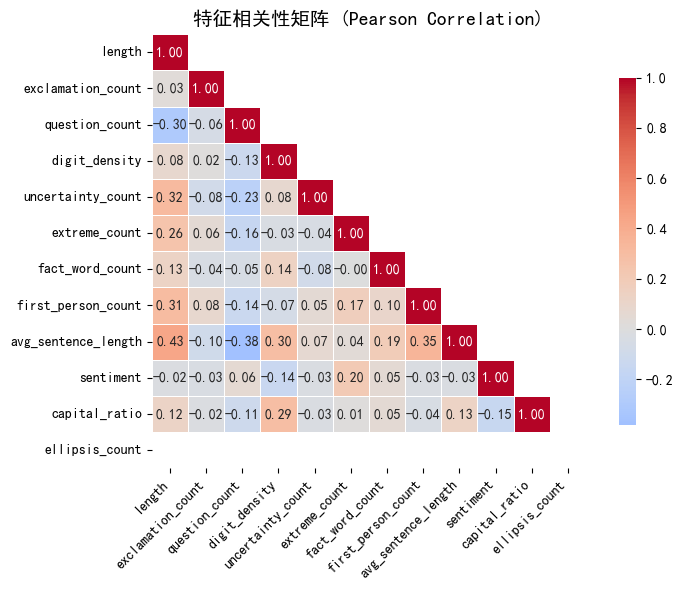


没有发现高度相关的特征对（|r| > 0.7）。


In [12]:
# 特征相关性热力图
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 假设 df_features 已经存在（来自之前的特征提取）
# 如果变量不存在，请先运行数据加载和特征提取代码
try:
    df_features
except NameError:
    print("df_features 未找到，请先运行特征提取代码。")
    # 可选：直接重新加载数据并提取特征（需要你之前的数据加载代码）
    # 这里不自动加载，避免覆盖你的已有变量
    raise

# 计算相关性矩阵（皮尔逊相关系数）
corr_matrix = df_features.corr()

# 设置图形大小
plt.figure(figsize=(8, 6))

# 绘制热力图
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # 只显示下三角，避免重复
sns.heatmap(corr_matrix, 
            mask=mask,
            annot=True,        # 显示数值
            fmt='.2f',         # 保留两位小数
            cmap='coolwarm',   # 红蓝配色
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})

plt.title('特征相关性矩阵 (Pearson Correlation)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('feature_correlation_heatmap.png', dpi=150)
plt.show()

# 找出高度相关的特征对（|r| > 0.7）
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.7:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], r))

if high_corr_pairs:
    print("\n高度相关的特征对 (|r| > 0.7)：")
    for f1, f2, r in high_corr_pairs:
        print(f"  {f1} — {f2}: {r:.3f}")
else:
    print("\n没有发现高度相关的特征对（|r| > 0.7）。")

In [18]:
# ========== 3. 特征模型训练 ==========
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n[模型训练]")
models = {
    '逻辑回归': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    '随机森林': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
}
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    results[name] = {'model': model, 'accuracy': acc, 'auc': auc, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"\n{name}: 准确率={acc:.4f}, AUC={auc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['事实', '谣言']))


[模型训练]

逻辑回归: 准确率=0.9200, AUC=0.9295
              precision    recall  f1-score   support

          事实       0.92      0.92      0.92        12
          谣言       0.92      0.92      0.92        13

    accuracy                           0.92        25
   macro avg       0.92      0.92      0.92        25
weighted avg       0.92      0.92      0.92        25


随机森林: 准确率=0.8800, AUC=0.9359
              precision    recall  f1-score   support

          事实       0.85      0.92      0.88        12
          谣言       0.92      0.85      0.88        13

    accuracy                           0.88        25
   macro avg       0.88      0.88      0.88        25
weighted avg       0.88      0.88      0.88        25



In [15]:
# ========== 4. 特征重要性（随机森林） ==========
rf_model = results['随机森林']['model']
importance_df = pd.DataFrame({'feature': df_features.columns, 'importance': rf_model.feature_importances_}).sort_values('importance', ascending=False)
print("\n特征重要性 Top 10:")
print(importance_df.head(10).to_string(index=False))


特征重要性 Top 10:
            feature  importance
             length    0.390598
avg_sentence_length    0.184814
          sentiment    0.116229
     question_count    0.088144
      digit_density    0.057530
 first_person_count    0.037955
  uncertainty_count    0.035556
      capital_ratio    0.035211
      extreme_count    0.024678
  exclamation_count    0.017386


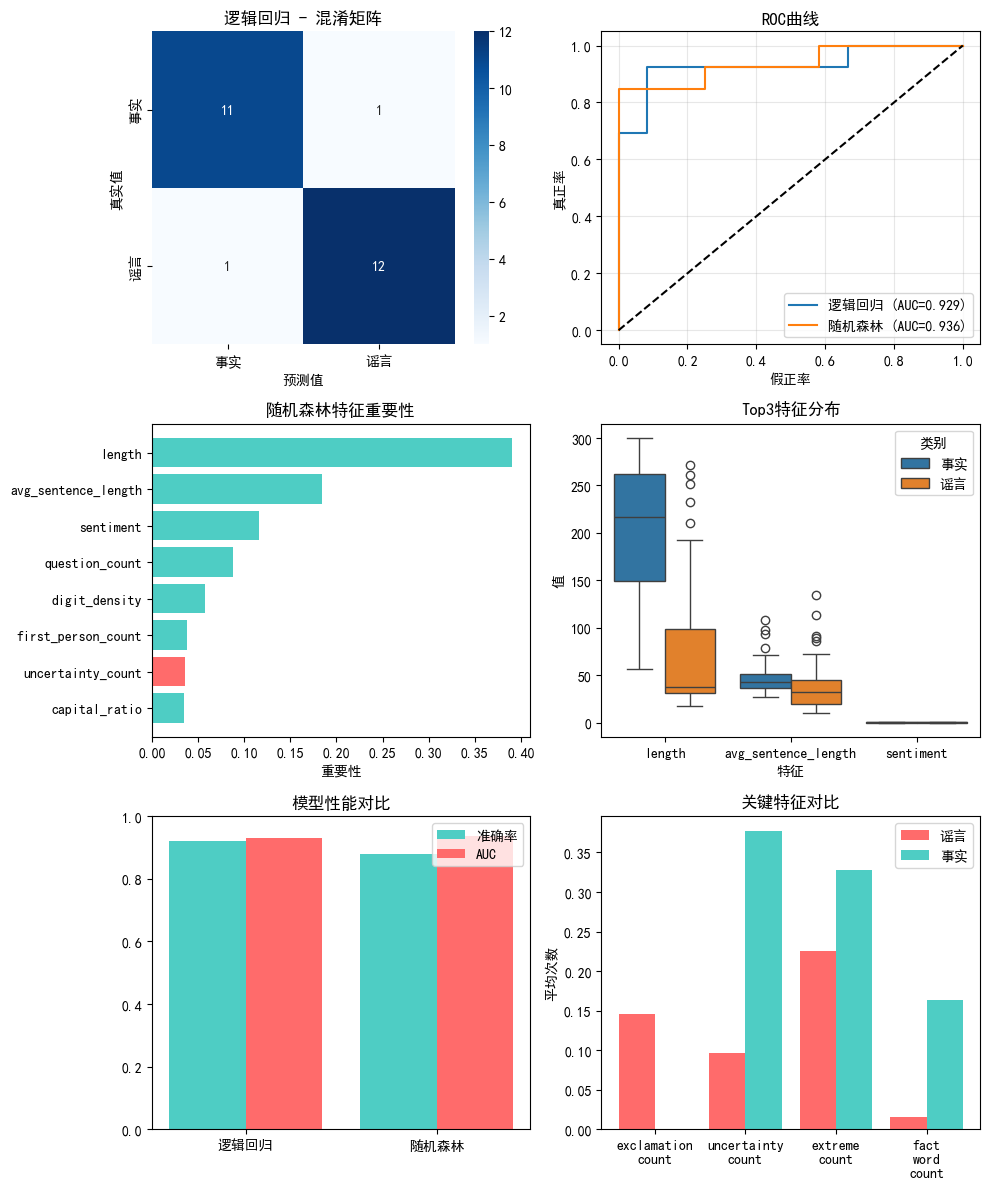

In [16]:
# ========== 5. 可视化 ==========
fig = plt.figure(figsize=(10, 12))
# 混淆矩阵
ax1 = plt.subplot(3, 2, 1)
cm = confusion_matrix(y_test, results['逻辑回归']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1, xticklabels=['事实','谣言'], yticklabels=['事实','谣言'])
ax1.set_xlabel('预测值')
ax1.set_ylabel('真实值')
ax1.set_title('逻辑回归 - 混淆矩阵')
# ROC曲线
ax2 = plt.subplot(3, 2, 2)
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    ax2.plot(fpr, tpr, label=f"{name} (AUC={res['auc']:.3f})")
ax2.plot([0,1],[0,1],'k--')
ax2.set_xlabel('假正率'); ax2.set_ylabel('真正率'); ax2.legend(); ax2.grid(True,alpha=0.3)
ax2.set_title('ROC曲线')
# 特征重要性
ax3 = plt.subplot(3, 2, 3)
top_feat = importance_df.head(8)
colors = ['#ff6b6b' if f in ['exclamation_count','uncertainty_count','extreme_count'] else '#4ecdc4' for f in top_feat['feature']]
ax3.barh(range(len(top_feat)), top_feat['importance'], color=colors)
ax3.set_yticks(range(len(top_feat))); ax3.set_yticklabels(top_feat['feature'])
ax3.set_xlabel('重要性'); ax3.set_title('随机森林特征重要性'); ax3.invert_yaxis()
# 特征分布箱线图
ax4 = plt.subplot(3, 2, 4)
top3 = importance_df.head(3)['feature'].tolist()
plot_data = []
for feat in top3:
    for label_val in [0,1]:
        vals = df_features[feat][y==label_val]
        for v in vals:
            plot_data.append({'特征':feat,'类别':'事实' if label_val==0 else '谣言','值':v})
sns.boxplot(x='特征', y='值', hue='类别', data=pd.DataFrame(plot_data), ax=ax4)
ax4.set_title('Top3特征分布')
# 模型性能对比
ax5 = plt.subplot(3, 2, 5)
x = np.arange(len(results))
accs = [results[n]['accuracy'] for n in results.keys()]
aucs = [results[n]['auc'] for n in results.keys()]
ax5.bar(x-0.2, accs, 0.4, label='准确率', color='#4ecdc4')
ax5.bar(x+0.2, aucs, 0.4, label='AUC', color='#ff6b6b')
ax5.set_xticks(x); ax5.set_xticklabels(results.keys()); ax5.set_ylim(0,1); ax5.legend(); ax5.set_title('模型性能对比')
# 谣言 vs 事实特征均值
ax6 = plt.subplot(3, 2, 6)
feat_compare = ['exclamation_count','uncertainty_count','extreme_count','fact_word_count']
rumor_means = [df_features[f][y==1].mean() for f in feat_compare]
fact_means = [df_features[f][y==0].mean() for f in feat_compare]
x = np.arange(len(feat_compare))
ax6.bar(x-0.2, rumor_means, 0.4, label='谣言', color='#ff6b6b')
ax6.bar(x+0.2, fact_means, 0.4, label='事实', color='#4ecdc4')
ax6.set_xticks(x); ax6.set_xticklabels([f.replace('_','\n') for f in feat_compare])
ax6.set_ylabel('平均次数'); ax6.set_title('关键特征对比'); ax6.legend()
plt.tight_layout()
plt.savefig('rumor_detection_results.png', dpi=150)
plt.show()

In [17]:
# ========== 9. 典型案例 ==========
print("\n典型案例展示（感叹号最多的谣言 vs 数字密度最高的事实）")
# 找出谣言中感叹号最多的
rumor_indices = [i for i, l in enumerate(y) if l==1]
if rumor_indices:
    exclamations = [df_features.iloc[i]['exclamation_count'] for i in rumor_indices]
    max_exclam_idx = rumor_indices[np.argmax(exclamations)]
    print(f"\n【典型谣言】感叹号={df_features.iloc[max_exclam_idx]['exclamation_count']}")
    print(unique_texts[max_exclam_idx][:200], "...")
fact_indices = [i for i, l in enumerate(y) if l==0]
if fact_indices:
    digit_densities = [df_features.iloc[i]['digit_density'] for i in fact_indices]
    max_digit_idx = fact_indices[np.argmax(digit_densities)]
    print(f"\n【典型事实】数字密度={df_features.iloc[max_digit_idx]['digit_density']:.3f}")
    print(unique_texts[max_digit_idx][:200], "...")

# ========== 10. 交叉验证 ==========
print("\n5折交叉验证:")
X_scaled_all = scaler.fit_transform(X)
for name, model in models.items():
    scores = cross_val_score(model, X_scaled_all, y, cv=5, scoring='accuracy')
    print(f"{name}: 平均准确率={scores.mean():.4f} (+/- {scores.std()*2:.4f})")

print("\n分析完成！")


典型案例展示（感叹号最多的谣言 vs 数字密度最高的事实）

【典型谣言】感叹号=4.0
网上有一个流传得比较广的贴子：“独家最新报道！美国华裔专家（吴教授）揭秘绝大多数医生都不知道的新冠病毒肺炎机理及自救措施！必看！救人救己！”其中提到，在受感染后的早期，应该针对过度免疫反应产生的过量氧自由基和炎症因子进行用药，应大剂量服用抗氧化剂，维生素C、E，以及板蓝根、金银花等都是很好的抗氧化清除自由基药物。 ...

【典型事实】数字密度=0.073
根据国家标准，一星级消毒柜消毒210分钟可以灭活甲型流感病毒，二星级消毒柜消毒150分钟可以灭活甲型流感病毒，但目前并无臭氧灭活SARS病毒和新冠病毒的数据，也没有数据证实臭氧消毒后口罩可以维持消毒前的防护功效。 如果要消毒一次性口罩，单次干热法消毒（70摄氏度加热30分钟）是可行的方法，灭活病毒并且不影响防护效果，但没有实验数据显示N95口罩可以在不影响防护效果的情况下干热消毒多少次，家庭做到稳 ...

5折交叉验证:
逻辑回归: 平均准确率=0.8777 (+/- 0.1152)
随机森林: 平均准确率=0.8530 (+/- 0.0873)

分析完成！
